# Visión por computadora

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Este cuaderno contiene una copia completa de `clasificar_frutas.py` y sus salidas reales. Ejecuta todas las celdas en orden, desde esta carpeta. La explicación y el análisis están en [README.md](README.md). Los archivos de entrada están en `datos/` cuando corresponda.

El código fuente principal se conserva en el archivo `.py`; `herramientas/generar_cuadernos.py` regenera y ejecuta este cuaderno después de cambiarlo.

In [1]:
import os, sys
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
# Las rutas y argumentos equivalen a ejecutar el script desde esta carpeta.
__file__ = str(Path.cwd() / 'clasificar_frutas.py')
sys.argv = [__file__]

In [2]:
"""Clasificación de fotos del taller con histogramas HSV y regresión logística."""
import csv
import hashlib
import json
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

HERE=Path(__file__).parent


def caracteristicas(ruta):
    with Image.open(ruta) as img:
        hsv=np.asarray(img.convert("RGB").resize((96,96)).convert("HSV"),dtype=np.float32)/255
    hist=[]
    for k in range(3):
        h,_=np.histogram(hsv[:,:,k],bins=16,range=(0,1),density=False)
        hist.extend(h/h.sum())
    return np.r_[hist,hsv.mean(axis=(0,1)),hsv.std(axis=(0,1))]


def main():
    train=sorted((HERE/"datos/entrenamiento").glob("*/*")); test=sorted((HERE/"datos/pruebas").glob("*"))
    assert len(train)>=40 and len(test)==6
    hashes={hashlib.sha256(p.read_bytes()).hexdigest() for p in train}
    x=np.array([caracteristicas(p) for p in train]); y=np.array([p.parent.name for p in train])
    modelo=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=2430085))
    cv=StratifiedKFold(3,shuffle=True,random_state=2430085)
    scores=cross_val_score(modelo,x,y,cv=cv); modelo.fit(x,y)
    salida=HERE/"resultados"; salida.mkdir(exist_ok=True)
    print(f"Entrenamiento: {len(train)} fotos; clases: {', '.join(sorted(set(y)))}.")
    print(f"Validación cruzada estratificada (3 pliegues): {scores.mean():.2%}. Fotos de la misma sesión: estimación orientativa.")
    filas=[]; fig,axes=plt.subplots(2,3,figsize=(11,7))
    for archivo,ax in zip(test,axes.flat):
        pred=str(modelo.predict([caracteristicas(archivo)])[0]); real="limon" if "Limon" in archivo.name else "naranja"
        duplicada=hashlib.sha256(archivo.read_bytes()).hexdigest() in hashes
        filas.append({"archivo":archivo.name,"real":real,"prediccion":pred,"acierto":pred==real,"repetida_en_train":duplicada})
        with Image.open(archivo) as foto: ax.imshow(foto)
        ax.axis("off"); ax.set_title(f"Real: {real} | pred: {pred}\n{'Repetida: excluida de métrica' if duplicada else 'Prueba diferente'}",fontsize=10)
        print(f"{archivo.name}: pred={pred}; real={real}; repetida={duplicada}")
    fig.tight_layout(); fig.savefig(salida/"predicciones.png",dpi=130); plt.close(fig)
    independientes=[r for r in filas if not r["repetida_en_train"]]
    aciertos=sum(r["acierto"] for r in independientes)
    metricas={"fotos_entrenamiento":len(train),"fotos_prueba":len(test),"repetidas_excluidas":len(filas)-len(independientes),"pruebas_diferentes":len(independientes),"aciertos_pruebas_diferentes":aciertos,"exactitud_pruebas_diferentes":aciertos/len(independientes),"validacion_cruzada":scores.tolist(),"limitacion":"Solo cuatro pruebas diferentes de limón/naranja; no miden generalización ni la clase fondo."}
    with (salida/"predicciones.csv").open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=filas[0]); w.writeheader(); w.writerows(filas)
    (salida/"metricas.json").write_text(json.dumps(metricas,ensure_ascii=False,indent=2),encoding="utf-8")
    np.savez_compressed(salida/"modelo.npz",media=modelo[0].mean_,escala=modelo[0].scale_,coeficientes=modelo[1].coef_,intercepto=modelo[1].intercept_,clases=modelo[1].classes_)
    print(f"Evaluación excluyendo fotos repetidas: {aciertos}/{len(independientes)} aciertos.")
    print("El cambio de luz/fondo puede degradar un clasificador basado en color.")


if __name__=="__main__": main()


Entrenamiento: 47 fotos; clases: fondo, limon, naranja.
Validación cruzada estratificada (3 pliegues): 93.75%. Fotos de la misma sesión: estimación orientativa.
Prueba_Limon_Fondo_Diferente.jpeg: pred=limon; real=limon; repetida=False
Prueba_Limon_No_Luz.jpeg: pred=limon; real=limon; repetida=False


Prueba_Limon_Original.jpeg: pred=limon; real=limon; repetida=True
Prueba_Naranja_Fondo_Diferente.jpeg: pred=limon; real=naranja; repetida=False
Prueba_Naranja_No_Luz.jpeg: pred=naranja; real=naranja; repetida=False
Prueba_Naranja_Original.jpeg: pred=naranja; real=naranja; repetida=True


Evaluación excluyendo fotos repetidas: 3/4 aciertos.
El cambio de luz/fondo puede degradar un clasificador basado en color.


## Imágenes producidas por esta ejecución

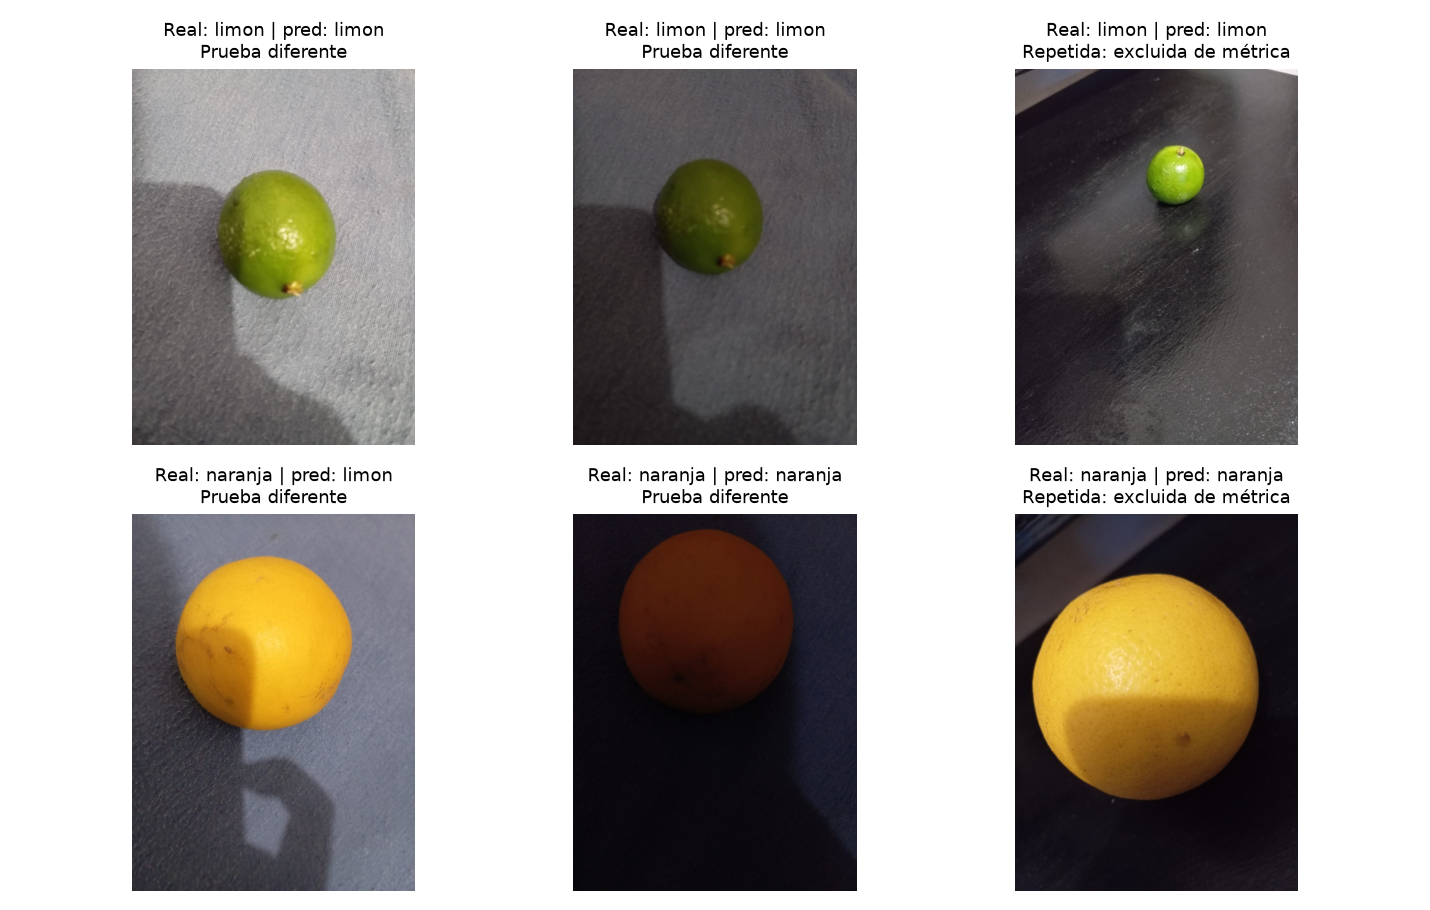

In [3]:
from IPython.display import display, Image
display(Image(filename='resultados/predicciones.png'))